<a href="https://colab.research.google.com/github/data-better/problab/blob/master/dice_sim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 주사위 눈금별 상대도수에 대한 히스토그램

In [1]:
#install.packages("ggplot2")
#install.packages("magrittr")
library(ggplot2)
library(magrittr)

In [3]:
# 주사위 던지기 함수
RDice = function(nn)  { return (table(factor(sample(1:6, nn, replace=TRUE), levels = 1:6)) / nn) }

In [4]:
set.seed(1234567)
dice_1 = RDice(12)
dice_2 = RDice(120)
dice_3 = RDice(1200)
dice_4 = RDice(12000)

In [5]:
# data transformation
dice = c(as.numeric(dice_1), as.numeric(dice_2), as.numeric(dice_3),
         as.numeric(dice_4))
nn   = c(rep("(a) n=12",6),rep("(b) n=120",6), rep("(c) n=1,200",6),
         rep("(d) n=12,000",6))
num = c(rep(1:6,4))
dice_result = data.frame(nn, num, dice)

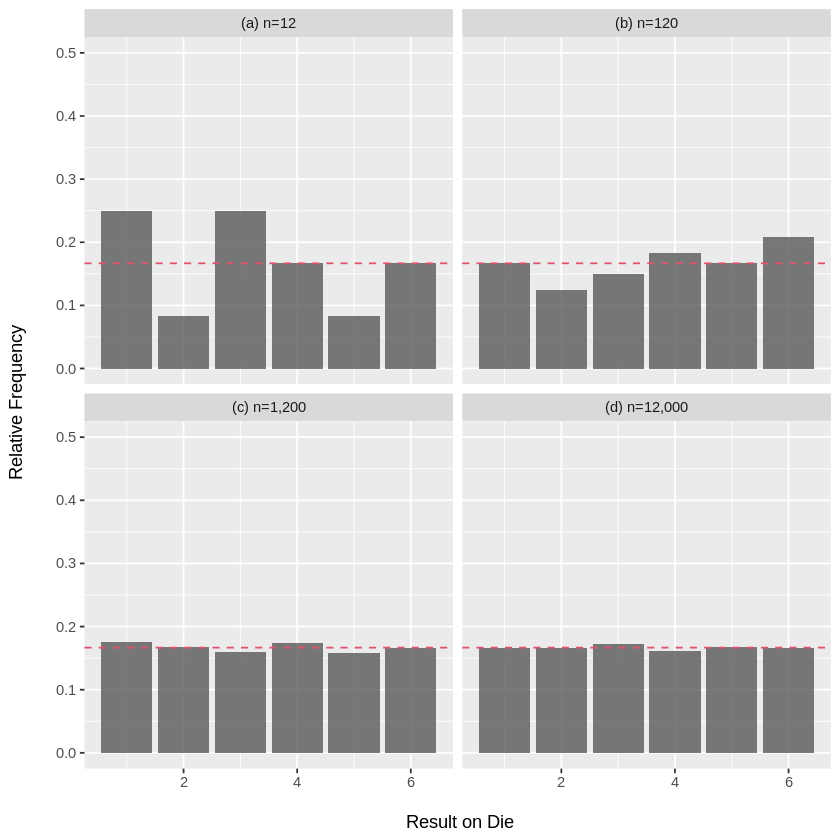

In [6]:
# ggplot2
ggplot(data = dice_result, aes(x = num, y = dice)) +
 geom_bar(stat = "identity", alpha = 0.8) +
 xlab("\n Result on Die") + ylab("Relative Frequency\n") +
 geom_hline(yintercept = 1/6, colour=2, lty=2) +
 ylim(0,0.5) + facet_wrap(~nn, ncol = 2)